In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import sys
import math
from pathlib import Path
import numpy as np
import torch.nn as nn
import torch
import matplotlib.pyplot as plt
from natsort import natsorted
from matplotlib.animation import FuncAnimation 
from IPython.display import HTML
from utils import *
from fit_alpha import MIMODataset, alpha_loss, train
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from Condition_model.forecasting import forecast_analysis
from Condition_model.samplers import CondSampler
from Condition_model.train import SAVE_PATH
from utils import temporal_difference, plot_temporal_difference
from tqdm.auto import tqdm 




# Jupyter CWD is the notebook's folder (Analysis/), so ".." is the project root
sys.path.insert(0, str(Path().resolve().parent))
# Path() means the current working directory
# resolve() make it absolute but there is no parameter in Path(), so it's actually adundant
# sys.path is a list, python would search this list once it's going to import a module

from Condition_model import samplers, dataset, forecasting, utils

physical_data_path = DATA_PATH / 'data_500traj'
test_phy_data_path = DATA_PATH / 'test'
invert_data_path = DATA_PATH / 'invert' / 'invert_steps=100'
test_invert_data_path = DATA_PATH / 'invert' / 'test'

Z, traj, anchor = load_invert(invert_data_path)
Z_test, traj_test, anchor_test = load_invert(test_invert_data_path)
# num of trajectories
N, L, C, H, W = Z.shape
# lead time but in vector
leads = [l for l in range(L)]
# total dimension
d = math.prod(Z.shape)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')




In [2]:
# test dataset class
train_ds = MIMODataset(Z, traj, anchor, physical_data_path, split='train')
train_loader = DataLoader(batch_size=16, dataset=train_ds, shuffle=True)

for batch in train_loader:
    print("Batch contents:")
    if isinstance(batch, (list, tuple)):
        for i, item in enumerate(batch):
            print(f"  Item {i}: shape {item.shape}, dtype {item.dtype}")
    else:
        print(f"  Shape: {batch.shape}, dtype {batch.dtype}")
    break  # Only check first batch

# define validation dataset

val_ds = MIMODataset(Z, traj, anchor, physical_data_path, split='val')
val_loader = DataLoader(batch_size=64, dataset=val_ds, shuffle=False)


Batch contents:
  Item 0: shape torch.Size([16, 2, 64, 64]), dtype torch.float32
  Item 1: shape torch.Size([16, 24, 2, 64, 64]), dtype torch.float32
  Item 2: shape torch.Size([16, 2]), dtype torch.float32


In [3]:

# build the model
# if we gonna apply MIMO we don't really need to customize the model class
# QUESTION: would spatital feature of x0 be helpful to forecast eps_t?
model = nn.Sequential(
    # why kernel_size is 3?
    nn.Conv2d(2, 16, kernel_size=3, padding=1),
    # I think ReLU makes sense
    # the correlation should be positive
    nn.ReLU(),
    # kernel_size of max_pool2d is 2*2
    # H -> H/2, W -> W/2
    nn.MaxPool2d(2),                                 # 64→32
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),                                 # 32→16
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),                         # Any size → (1, 1)
    nn.Flatten(),
    nn.Linear(64, 23),
    # constraint: alpha must in (0, 1)
    nn.Sigmoid()  
)

model

Sequential(
  (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): AdaptiveAvgPool2d(output_size=1)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=64, out_features=23, bias=True)
  (11): Sigmoid()
)

  0%|          | 0/100 [00:00<?, ?it/s]

Early stopping at epoch 69


/home/trace/Documents/Projects/Thesis/Analysis/fit_alpha.py:240: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pt'))


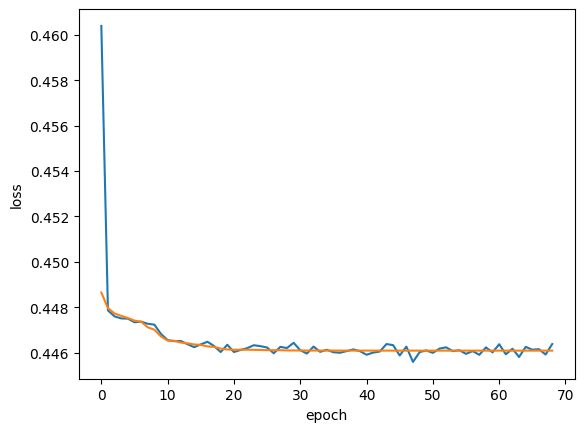

In [4]:
%matplotlib inline

optimizer = optim.Adam(model.parameters(), lr=0.001)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model, train_loss, val_loss = train(train_loader=train_loader, 
                                    val_loader=val_loader, 
                                    optimizer=optimizer, 
                                    epochs=100, 
                                    patience=10, 
                                    model=model,
                                    device=device)


In [5]:
# load the model
model.load_state_dict(torch.load('best_model.pt'))
model.to(device)

/tmp/ipykernel_108592/1630610371.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pt'))


Sequential(
  (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): AdaptiveAvgPool2d(output_size=1)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=64, out_features=23, bias=True)
  (11): Sigmoid()
)

In [6]:
bs = 5
sample_shape = (C, H, W)


test_dataset = MIMODataset(Z_test, traj_test, anchor_test, test_phy_data_path, split='test')
test_meta = test_dataset.meta
# print(f"I'm not sure what test_meta would look like {test_meta.shape}")
test_loader = DataLoader(batch_size=bs, dataset=test_dataset, shuffle=False)
n_bs = len(test_loader)

test_loss = 0
test_samples =  0 
# what about x0s, for each batch it's in (bs, 2, 64, 64) 
alphas = torch.empty((n_bs, bs, L-1))
x0s = torch.empty((n_bs, bs, *sample_shape))
ens = 5
sampler = CondSampler(device=device, steps=100, model_path=SAVE_PATH)



#PROBLEM: out of memory...
# what you can do is you store everything
for i, batch in enumerate(test_loader):
    x0, z, _ = batch
    # before to(device)
    x0s[i] = x0
    x0, z = x0.to(device), z.to(device)
    alpha = model(x0)  # (bs, 23)
    loss = alpha_loss(alpha, z)
    test_loss += loss.item() * bs
    test_samples += bs
    alphas[i] = alpha.cpu()

alphas = alphas.view(-1, L-1)
x0s = x0s.view(-1, *sample_shape)

avg_test = test_loss / test_samples
avg_test

0.4577065333724022

In [7]:
preds = torch.empty((n_bs*bs, ens, L,  *sample_shape))

shape_check = True
for i, alpha in enumerate(tqdm(alphas)):
    # (n_bs*bs, 23)
    latent_shape = (1, ens, L, *sample_shape)
    latents = get_latents(latent_shape=latent_shape, alpha=alpha, device=device, markov=True)
    latents = latents.reshape(ens * L, *sample_shape)  
    x0 = x0s[i].repeat(ens * L, 1, 1, 1)
    lead_time = torch.arange(1, 25, dtype=torch.float32) / L
    time_labels = lead_time.repeat(ens)

    if shape_check:
        assert latents.shape == (ens*L, *sample_shape), f'latents shape error, {latents.shape}'
        assert x0.shape == (ens*L, *sample_shape), f'x0 shape error, {x0.shape}'
        assert time_labels.numel() == ens*L, f'time shape error, {time_labels.shape}'
        shape_check = False

    pred = sampler.sample(z0=latents, x_t=x0, lead_times=time_labels)
    pred = pred.reshape(ens, L, *sample_shape).contiguous()
    preds[i] = pred

# it wouldn't shuffle anyway
# just get truths once, more efficient in this way
truths = get_window(test_meta, test_phy_data_path)
assert preds[:, 0, ...].shape == truths.shape, "Each ensemble member of prediction should keep the same dimension with truth."



  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

<Axes: xlabel='lag t', ylabel='difference'>

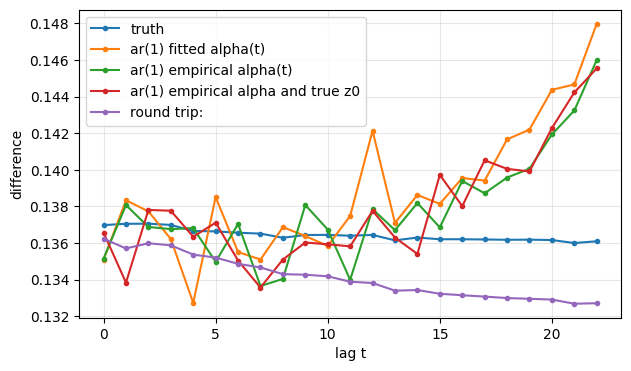

In [8]:
# is alpha can fit difference?
# I need another line to examine the joint Gaussian or linear estimator gap

emp_test_alpha = compute_alpha(Z_test)

latent_shape = (emp_test_alpha.shape[0], ens, L ,*sample_shape)
latents = get_latents(latent_shape, emp_test_alpha, device, markov=True)


emp_preds = torch.empty((n_bs*bs, ens, L,  *sample_shape))
jg_preds = torch.empty((n_bs*bs, ens, L,  *sample_shape))


shape_check = True
for i, alpha in enumerate(tqdm(emp_test_alpha)):
    # this is used to examine the joint Gaussian assumption
    # this wired slice would keep the first dimension as 1
    z0s = torch.as_tensor(Z_test[i:i+1, 0, ...]) # (1, 2, 64, 64)  
    z0s = z0s[:, None, ...].repeat(1, ens, 1, 1, 1) # (1, ens, 2, 64, 64)
    # (n_bs*bs, 23)
    latent_shape = (1, ens, L, *sample_shape)
    x0 = x0s[i].repeat(ens * L, 1, 1, 1)
    lead_time = torch.arange(1, 25, dtype=torch.float32) / L
    time_labels = lead_time.repeat(ens)
    # latent to examine the JG
    latents_JG = get_latents(latent_shape=latent_shape, alpha=alpha, device=device, markov=True, z0=z0s)
    latents_JG = latents_JG.reshape(ens * L, *sample_shape)  

    latents = get_latents(latent_shape=latent_shape, alpha=alpha, device=device, markov=True)
    latents = latents.reshape(ens * L, *sample_shape)  


    if shape_check:
        assert latents.shape == (ens*L, *sample_shape), f'latents shape error, {latents.shape}'
        assert x0.shape == (ens*L, *sample_shape), f'x0 shape error, {x0.shape}'
        assert time_labels.numel() == ens*L, f'time shape error, {time_labels.shape}'
        shape_check = False

    jg_pred = sampler.sample(z0=latents_JG, x_t=x0, lead_times=time_labels)
    jg_pred = jg_pred.reshape(ens, L, *sample_shape).contiguous()
    jg_preds[i] = jg_pred

    emp_pred = sampler.sample(z0=latents, x_t=x0, lead_times=time_labels)
    emp_pred = emp_pred.reshape(ens, L, *sample_shape).contiguous()
    emp_preds[i] = emp_pred

# truths are same
emp_preds_diff = temporal_difference(emp_preds)
jg_preds_diff = temporal_difference(jg_preds)
pred_diff = temporal_difference(preds)
truth_diff = temporal_difference(truths)

diff_dict = {'truth': truth_diff, 
            'ar(1) fitted alpha(t)': pred_diff,
            'ar(1) empirical alpha(t)': emp_preds_diff,
            'ar(1) empirical alpha and true z0': jg_preds_diff}


# Round trip should be the real ground truth
N_test = x0s.shape[0]

round_trip = torch.empty((N_test, L,  *sample_shape))
for i in tqdm(range(N_test)):
    z = torch.as_tensor(Z_test[i]) # (24, 2, 64, 64)  
    x0 = x0s[i].repeat(L, 1, 1, 1) # (24, 2, 64, 64)
    lead_time = torch.arange(1, 25, dtype=torch.float32) / L
    rt_pred = sampler.sample(z0=z, x_t=x0, lead_times=lead_time)
    round_trip[i] = rt_pred
    
rt_pred_diff = temporal_difference(round_trip)
diff_dict['round trip:'] = rt_pred_diff

%matplotlib inline
plot_temporal_difference(diff_dict)



